# IT3091 – Machine Learning Group Assignment
##  Data Quality, EDA and Preprocessing

### Project: Rice Variety Classification and QC Decision Support

### Objectives
1. Verify dataset quality and completeness.
2. Identify missing values, duplicates, invalid values and outliers.
3. Investigate class imbalance and feature distributions.
4. Prepare training and testing data.
5. Design preprocessing without data leakage.
6. Document preprocessing decisions for Person 3.

### Connection to Person 1
Person 1 identified differences between Cammeo and Osmancik
rice varieties and investigated correlations between features.

This stage verifies data quality and prepares the dataset
for reliable machine learning model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Rice_Cammeo_Osmancik.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


In [2]:
# Step 2: Missing Value Analysis

missing_count = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

display(missing_summary)

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Count,Missing Percentage (%)
Area,0,0.0
Perimeter,0,0.0
Major_Axis_Length,0,0.0
Minor_Axis_Length,0,0.0
Eccentricity,0,0.0
Convex_Area,0,0.0
Extent,0,0.0
Class,0,0.0


Total Missing Values: 0


### Missing Value Analysis — Interpretation

The dataset contains no missing values across the seven
numerical features and the target variable.

Therefore, missing-value imputation is not required.
All 3,810 observations can be retained at this stage.

This finding supports data completeness, although
additional checks for duplicates, invalid measurements
and outliers are still necessary.

In [3]:
# Step 3: Duplicate Detection

duplicate_count = df.duplicated().sum()

print("Total Rows:", len(df))
print("Fully Duplicated Rows:", duplicate_count)
print("Duplicate Percentage:",
      round((duplicate_count / len(df)) * 100, 2), "%")

# Display duplicate rows if any exist
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No fully duplicated rows found.")

Total Rows: 3810
Fully Duplicated Rows: 0
Duplicate Percentage: 0.0 %
No fully duplicated rows found.


### Duplicate Detection — Interpretation

The dataset was examined for fully duplicated observations
across all eight columns.

No fully duplicated records were identified.

Therefore, no duplicate removal is required at this stage.
All 3,810 observations are retained.

In [5]:
# Step 4: Data Type and Invalid Value Analysis

numeric_features = [
    "Area",
    "Perimeter",
    "Major_Axis_Length",
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Extent"
]

# 1. Check data types
print("DATA TYPES")
print(df.dtypes)



DATA TYPES
Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                 object
dtype: object


In [6]:
# 2. Check invalid numerical values
print("\nINFINITE VALUES")
print(np.isinf(df[numeric_features]).sum())




INFINITE VALUES
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
dtype: int64


In [7]:
# 3. Check zero or negative measurements
print("\nZERO OR NEGATIVE VALUES")
print((df[numeric_features] <= 0).sum())




ZERO OR NEGATIVE VALUES
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
dtype: int64


In [8]:
# 4. Check valid ranges
print("\nFEATURE RANGES")
display(df[numeric_features].agg(["min", "max"]).T)




FEATURE RANGES


,min,max
Area,7551.000000,18913.000000
Perimeter,359.100006,548.445984
Major_Axis_Length,145.264465,239.010498
Minor_Axis_Length,59.532406,107.542450
Eccentricity,0.777233,0.948007
Convex_Area,7723.000000,19099.000000
Extent,0.497413,0.861050


In [9]:
# 5. Check target labels
print("\nCLASS LABELS")
print(df["Class"].value_counts(dropna=False))


CLASS LABELS
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64


In [10]:
print("Convex_Area smaller than Area:",
      (df["Convex_Area"] < df["Area"]).sum())

Convex_Area smaller than Area: 0


### Data Validity Interpretation

All seven input features have numerical data types (`float64`), while the target variable contains the two expected rice varieties: Cammeo and Osmancik.

No infinite, zero or negative numerical values were detected. Eccentricity and Extent fall within their expected ranges of 0 to 1.

These findings indicate that the dataset passes the numerical validity checks performed. No correction or removal is required based on these checks. Outlier analysis will be conducted separately to investigate unusual but potentially valid grain measurements.

In [11]:
# Step 5: IQR-Based Outlier Detection

numeric_features = df.drop(columns=["Class"])

Q1 = numeric_features.quantile(0.25)
Q3 = numeric_features.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers for each feature
outlier_flags = (
    (numeric_features < lower_bound) |
    (numeric_features > upper_bound)
)

outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_flags.sum(),
    "Outlier Percentage (%)": (
        outlier_flags.mean() * 100
    ).round(2)
})

display(outlier_summary)

# Count unique rows with at least one flagged feature
print(
    "Rows with at least one outlier:",
    outlier_flags.any(axis=1).sum()
)

,Outlier Count,Outlier Percentage (%)
Area,4,0.10
Perimeter,0,0.00
Major_Axis_Length,0,0.00
Minor_Axis_Length,65,1.71
Eccentricity,21,0.55
Convex_Area,3,0.08
Extent,0,0.00


Rows with at least one outlier: 85


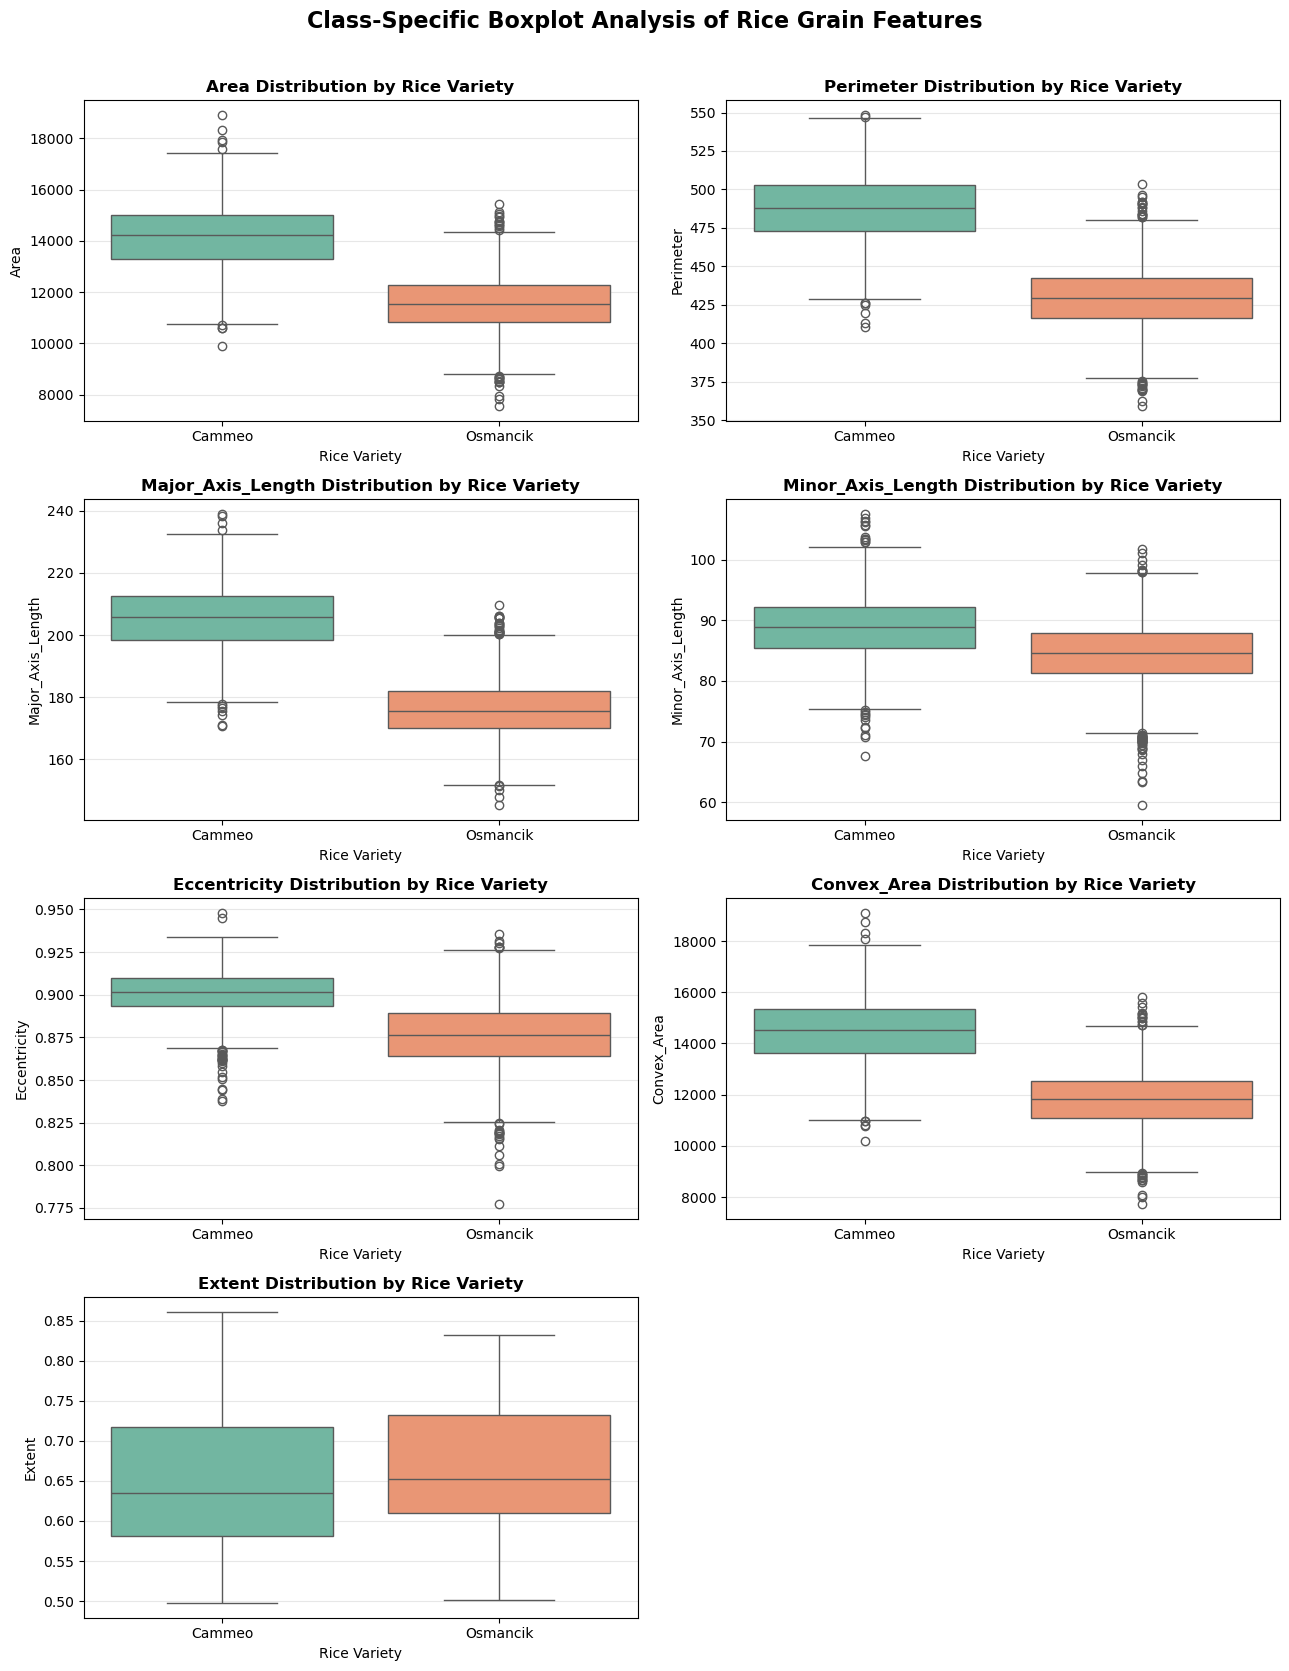

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "Area", "Perimeter", "Major_Axis_Length",
    "Minor_Axis_Length", "Eccentricity",
    "Convex_Area", "Extent"
]

fig, axes = plt.subplots(4, 2, figsize=(13, 17))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        palette="Set2",
        legend=False,
        ax=axes[i],
        showfliers=True
    )

    axes[i].set_title(
        f"{feature} Distribution by Rice Variety",
        fontsize=12,
        fontweight="bold"
    )
    axes[i].set_xlabel("Rice Variety")
    axes[i].set_ylabel(feature)
    axes[i].grid(axis="y", alpha=0.3)

axes[7].axis("off")

plt.suptitle(
    "Class-Specific Boxplot Analysis of Rice Grain Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Outlier Analysis 

Class-specific boxplots revealed differences in grain morphology
between Cammeo and Osmancik rice varieties.

Area, Perimeter, Major_Axis_Length and Convex_Area generally
showed higher values for Cammeo. Minor_Axis_Length and Extent
showed greater overlap between the varieties.

The pooled IQR analysis flagged 85 observations (2.23%).
Class-specific boxplots revealed additional potential outliers.

Since these observations may represent natural grain variation
rather than measurement errors, no outlier removal was performed.



### Outlier Handling Decision

The IQR method identified 85 observations (2.23%) with at least one potential outlier. However, the data-quality checks did not reveal invalid measurements, missing values or duplicated records.

Since the dataset represents physical rice grain measurements, extreme observations may reflect genuine natural variation rather than errors.

Therefore, no outliers were removed from the main dataset. All 3,810 observations were retained to preserve information and avoid unnecessary data loss.

Outlier removal was not assumed to improve model performance. Any future comparison involving outlier treatment should use training-data-only procedures and appropriate cross-validation to prevent data leakage.

In [14]:
# Stratified Train/Test Split

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training observations: 3048
Testing observations: 762

Training class distribution:
Class
Osmancik    1744
Cammeo      1304
Name: count, dtype: int64

Testing class distribution:
Class
Osmancik    436
Cammeo      326
Name: count, dtype: int64

Training class percentages:
Class
Osmancik    57.22
Cammeo      42.78
Name: proportion, dtype: float64

Testing class percentages:
Class
Osmancik    57.22
Cammeo      42.78
Name: proportion, dtype: float64


### Stratified Train/Test Split — Interpretation

The dataset was divided into 80% training data (3,048 observations)
and 20% testing data (762 observations).

Stratified sampling preserved the original class distribution:
57.22% Osmancik and 42.78% Cammeo in both subsets.

A fixed random state of 42 was used for reproducibility.

The test dataset will remain separate from preprocessing fitting,
feature selection, hyperparameter tuning and model development.

In [15]:
# Step 7: StandardScaler - Training Data Only

from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

# Learn mean and standard deviation from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the SAME transformation to test data
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Original training feature means:")
print(X_train.mean().round(2))

print("\nScaled training feature means:")
print(X_train_scaled.mean().round(4))

print("\nScaled training feature standard deviations:")
print(X_train_scaled.std(ddof=0).round(4))

Original training feature means:
Area                 12678.70
Perimeter              454.37
Major_Axis_Length      188.76
Minor_Axis_Length       86.40
Eccentricity             0.89
Convex_Area          12964.53
Extent                   0.66
dtype: float64

Scaled training feature means:
Area                 0.0
Perimeter            0.0
Major_Axis_Length    0.0
Minor_Axis_Length    0.0
Eccentricity         0.0
Convex_Area          0.0
Extent               0.0
dtype: float64

Scaled training feature standard deviations:
Area                 1.0
Perimeter            1.0
Major_Axis_Length    1.0
Minor_Axis_Length    1.0
Eccentricity         1.0
Convex_Area          1.0
Extent               1.0
dtype: float64


### Feature Scaling 

StandardScaler was applied to the training dataset to
demonstrate feature standardization.

After transformation, all seven training features had
means approximately equal to 0 and standard deviations
approximately equal to 1.

The scaler was fitted using training data only and then
applied to the test data without refitting.

This approach prevents test-set information from
influencing the scaling parameters.

For model development, scaling will be performed inside
scikit-learn Pipelines to prevent data leakage during
cross-validation.

The original unscaled X_train and X_test datasets will
be passed to Person 3 for model development.

In [16]:
# Step 9: Export data for Person 3

from pathlib import Path

output_dir = Path("person2_handover")
output_dir.mkdir(exist_ok=True)

# Keep original feature values
train_data = X_train.copy()
train_data["Class"] = y_train

test_data = X_test.copy()
test_data["Class"] = y_test

# Save the two datasets
train_data.to_csv(output_dir / "rice_train.csv", index=False)
test_data.to_csv(output_dir / "rice_test.csv", index=False)

print("Training dataset:", train_data.shape)
print("Testing dataset:", test_data.shape)
print("Handover files saved successfully.")

Training dataset: (3048, 8)
Testing dataset: (762, 8)
Handover files saved successfully.
